# Checkpoint 2: experimentos controlados com SVM

**Inteligência Artificial II · Arena de Personagens**
**Grupo:** Alceu Ferreira dos Santos Neto · Anthony Gabriel Schirato Lourenço · Gustavo de Carvalho Vieira ·
Luan Carlos de Souza Ferreira · Lucas Miguel Moreno Rios

**Pergunta de investigação (do Checkpoint 1):** um SVM, usando apenas informações conhecidas antes da batalha, consegue
prever o favorito de batalhas entre **Pokémon nunca vistos no treino**, superando regras simples?

Neste notebook:
1. Protocolo de avaliação e métricas (com justificativa)
2. Baselines
3. **Cinco experimentos controlados**, cada um com *hipótese → alteração → resultado → interpretação*
4. **Análise de erros** e casos inesperados
5. Conclusões provisórias e limitações

> **Hipóteses registradas antes dos experimentos:** E1 a E4 foram registradas no notebook `01_pipeline_duelo_svm.ipynb`
> (seção 8), em 20/10/2026, antes de qualquer execução destes experimentos. Elas estão repetidas abaixo, sem alteração
> de sentido, antes de cada experimento.

In [1]:
import sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

sys.path.insert(0, "../src")
from features import Extrator, COLS_BASE, COLS_GOLPES
from simulador import batalha, candidatos

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110
SEED = 42

## 1. Dados, divisões e features

- `pokemon.csv`: 1.242 Pokémon (PokéAPI); `batalhas.csv`: 40.000 confrontos com **golpes reais**, cada um simulado 21
  vezes (gerados pelo grupo, seed 42).
- **Divisão por Pokémon (sem vazamento):**

| Conjunto | Batalhas entre Pokémon das gerações | Uso |
|---|---|---|
| Treino | 1–6 | treinar os modelos |
| Ajuste (E3) | treino interno: 1–4 · validação: 5–6 | escolher C e gamma **sem tocar no teste** |
| **Teste** | 7–9 | avaliação final, **nunca usada para decidir nada** |

In [2]:
pk = pd.read_csv("../data/processed/pokemon.csv")
bt = pd.read_csv("../data/processed/batalhas.csv")
geracao = pk.set_index("pokeapi_id")["Generation"]
bt["gen_a"], bt["gen_b"] = bt.a_id.map(geracao), bt.b_id.map(geracao)

t0 = time.time()
X = Extrator(pk).tabela(bt)          # base (8) + golpes (7) = 15 features
y = bt.a_vence.values
print(f"Features calculadas em {time.time() - t0:.0f}s: {X.shape}")

treino = (bt.grupo == "treino").values
teste = (bt.grupo == "teste").values
ajuste_tr = treino & (bt.gen_a <= 4).values & (bt.gen_b <= 4).values
ajuste_val = treino & (bt.gen_a >= 5).values & (bt.gen_b >= 5).values
for nome, m in [("treino", treino), ("teste", teste), ("ajuste: treino interno", ajuste_tr), ("ajuste: validação", ajuste_val)]:
    print(f"{nome:<24} {m.sum():>6} batalhas | A vence {y[m].mean():.1%}")

Features calculadas em 13s: (40000, 15)
treino                    30000 batalhas | A vence 49.8%
teste                      6000 batalhas | A vence 49.0%
ajuste: treino interno    14205 batalhas | A vence 50.1%
ajuste: validação          2860 batalhas | A vence 50.1%


**Features**
| Grupo | Features | Significado |
|---|---|---|
| Base (Checkpoint 1) | `dif_HP` … `dif_Speed` | diferença de cada atributo (A − B) |
| | `log_mult_a`, `log_mult_b` | eficácia de tipo do golpe do próprio tipo de cada lado (log2) |
| **Golpes (novo, E2)** | `frac_a`, `frac_b` | fração do HP do adversário que o melhor golpe **que o Pokémon realmente aprende** tira por turno (média esperada) |
| | `nocaute_a`, `nocaute_b`, `dif_nocaute` | golpes necessários para nocautear o adversário, e a diferença |
| | `prioridade_a`, `prioridade_b` | se tem golpe de prioridade (ataca antes, mesmo sendo mais lento) |

Todas usam **só informação conhecida antes da batalha** (atributos, tipos e lista pública de golpes). O modelo não vê o
resultado das simulações nem a sorte.

## 2. Protocolo e métricas

| Métrica | Por que faz sentido aqui |
|---|---|
| **Acurácia** (principal) | As classes estão equilibradas (cerca de 50% "A vence"), então acurácia não é enganosa e é fácil de interpretar: "% de batalhas em que acertamos o favorito". |
| **F1** | Confirma que o modelo não favorece uma das classes (precisão e recall equilibrados). |
| **ROC-AUC** | Mede se o **score** do SVM ordena bem as batalhas (quanto maior, mais provável A vencer). Importa porque a aplicação mostra a **confiança** da previsão. |
| Teto de acerto | 5,7% das batalhas são equilibradas (A vence entre 30% e 70% das 21 simulações). Nelas, nenhum modelo acerta sempre, e um erro perto de 50% é esperado. |

Todos os modelos usam `StandardScaler` dentro de um `Pipeline` (média e desvio aprendidos só no treino).

In [3]:
resultados = {}

def avaliar(nome, modelo, cols, tr=treino, te=teste, guardar=True):
    t = time.time()
    modelo.fit(X.loc[tr, cols], y[tr])
    pred = modelo.predict(X.loc[te, cols])
    score = (modelo.decision_function(X.loc[te, cols]) if hasattr(modelo, "decision_function")
             else modelo.predict_proba(X.loc[te, cols])[:, 1])
    r = {"acurácia": accuracy_score(y[te], pred), "F1": f1_score(y[te], pred),
         "ROC-AUC": roc_auc_score(y[te], score), "tempo (s)": time.time() - t}
    if guardar:
        resultados[nome] = r
    return modelo, r

def tabela(nomes):
    return pd.DataFrame({n: resultados[n] for n in nomes}).T.round(3)

def svm(**kw):
    return make_pipeline(StandardScaler(), SVC(**kw))

## 3. Baselines

In [4]:
class Regra(BaseEstimator, ClassifierMixin):
    """A vence se a coluna for positiva; empate é sorteado (seed fixa)."""
    def __init__(self, coluna): self.coluna = coluna
    def fit(self, X, y): self.classes_ = np.array([0, 1]); return self
    def decision_function(self, X): return X[self.coluna].to_numpy(float)
    def predict(self, X):
        s = self.decision_function(X)
        return np.where(s > 0, 1, np.where(s < 0, 0, np.random.default_rng(SEED).integers(0, 2, len(s))))

X["dif_total"] = X[[c for c in COLS_BASE if c.startswith("dif_")]].sum(axis=1)
avaliar("Baseline: classe majoritária", DummyClassifier(strategy="most_frequent"), COLS_BASE)
avaliar("Baseline: vence o mais rápido", Regra("dif_Speed"), ["dif_Speed"])
avaliar("Baseline: vence o maior total", Regra("dif_total"), ["dif_total"])
avaliar("Baseline: Regressão Logística (base)", make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)), COLS_BASE)
tabela(list(resultados))

,acurácia,F1,ROC-AUC,tempo (s)
Baseline: classe majoritária,0.510,0.000,0.500,0.046
Baseline: vence o mais rápido,0.678,0.675,0.713,0.018
Baseline: vence o maior total,0.806,0.802,0.898,0.000
Baseline: Regressão Logística (base),0.856,0.853,0.936,0.035


## 4. Experimentos

### E1: Qual kernel separa melhor as batalhas?
- **Hipótese (registrada em 20/10):** a interação entre velocidade e tipo exige uma fronteira não linear, então o kernel
  **RBF** deve superar o **linear**.
- **Alteração:** apenas o kernel (linear, polinomial de grau 3, RBF). Mesmas features (base), mesmos dados, `C = 1`,
  `gamma = "scale"`.

In [5]:
modelos_e1 = {}
for k in ["linear", "poly", "rbf"]:
    modelos_e1[k], _ = avaliar(f"E1: SVM {k} (base)", svm(kernel=k), COLS_BASE)
tabela([f"E1: SVM {k} (base)" for k in ["linear", "poly", "rbf"]] + ["Baseline: Regressão Logística (base)"])

,acurácia,F1,ROC-AUC,tempo (s)
E1: SVM linear (base),0.856,0.853,0.936,12.006
E1: SVM poly (base),0.857,0.854,0.926,12.216
E1: SVM rbf (base),0.866,0.863,0.935,16.083
Baseline: Regressão Logística (base),0.856,0.853,0.936,0.035


**Resultado e interpretação (E1):** o RBF foi o melhor kernel (86,6%), mas só **1 ponto** acima do linear (85,6%) e
do polinomial (85,7%). O kernel linear empatou com a Regressão Logística, o que é esperado, porque os dois desenham uma
fronteira reta. **Hipótese confirmada, mas fraca:** existe alguma interação não linear (por exemplo, a velocidade importa
mais quando os dois nocauteiam rápido), mas a maior parte do problema é quase linear ("quem é mais forte e tem
vantagem de tipo vence"). O ROC-AUC praticamente igual (0,935 × 0,936) mostra que o RBF acerta um pouco mais a
classe, mas não ordena melhor a confiança.

### E2: Informar os golpes reais ao modelo melhora a previsão?
- **Hipótese (registrada em 20/10):** incluir features dos golpes que cada Pokémon realmente aprende recupera boa parte da
  queda de 92% para 87% causada pelos golpes reais (Checkpoint 1).
- **Alteração:** conjunto de features: **base (8)** × **base + golpes (15)**. Mesmo modelo (SVM RBF padrão). Para saber
  se o ganho vem das features ou do modelo, a Regressão Logística também é treinada com os dois conjuntos.

In [6]:
avaliar("E2: SVM rbf (base + golpes)", svm(kernel="rbf"), COLS_BASE + COLS_GOLPES)
avaliar("E2: Regressão Logística (base + golpes)", make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)), COLS_BASE + COLS_GOLPES)
avaliar("E2: SVM linear (base + golpes)", svm(kernel="linear"), COLS_BASE + COLS_GOLPES)
tabela(["E1: SVM rbf (base)", "E2: SVM rbf (base + golpes)", "Baseline: Regressão Logística (base)",
        "E2: Regressão Logística (base + golpes)", "E2: SVM linear (base + golpes)"])

,acurácia,F1,ROC-AUC,tempo (s)
E1: SVM rbf (base),0.866,0.863,0.935,16.083
E2: SVM rbf (base + golpes),0.926,0.924,0.976,12.365
Baseline: Regressão Logística (base),0.856,0.853,0.936,0.035
E2: Regressão Logística (base + golpes),0.918,0.916,0.976,0.050
E2: SVM linear (base + golpes),0.918,0.916,0.975,10.034


In [7]:
# Quais features de golpes mais importam? Retirar uma de cada vez (SVM rbf, mesmo protocolo)
importancia = {}
ref = resultados["E2: SVM rbf (base + golpes)"]["acurácia"]
for grupo, cols in {"sem frac (dano por turno)": ["frac_a", "frac_b"],
                    "sem nocaute (golpes p/ nocautear)": ["nocaute_a", "nocaute_b", "dif_nocaute"],
                    "sem prioridade": ["prioridade_a", "prioridade_b"]}.items():
    _, r = avaliar(grupo, svm(kernel="rbf"), [c for c in COLS_BASE + COLS_GOLPES if c not in cols], guardar=False)
    importancia[grupo] = {"acurácia": r["acurácia"], "queda": ref - r["acurácia"]}
pd.DataFrame(importancia).T.round(3)

,acurácia,queda
sem frac (dano por turno),0.924,0.002
sem nocaute (golpes p/ nocautear),0.909,0.017
sem prioridade,0.918,0.007


**Resultado e interpretação (E2):** as features de golpes levaram o SVM de **86,6% para 92,6%** (+6 pontos), e o
ROC-AUC de 0,935 para 0,976. **Hipótese confirmada:** a queda causada pelos golpes reais (92,1% → 86,6% no Checkpoint 1)
foi totalmente recuperada. O ganho vem principalmente das **features**, e não do modelo: a Regressão Logística também
subiu, de 85,6% para 91,8%. Com as novas features, o SVM RBF continua cerca de **0,8 ponto** acima dos modelos lineares.

A retirada de cada grupo de features mostra que a mais importante é **quantos golpes cada um precisa para nocautear o
outro** (sem ela, a acurácia cai 1,7 ponto). Isso faz sentido: em uma batalha 1 contra 1, o que decide é quem derruba
o outro primeiro.

### E3: Ajustar C e gamma melhora o modelo?
- **Hipótese (registrada em 20/10):** os valores padrão (`C = 1`, `gamma = "scale"`) não são os melhores. Ajustá-los
  com validação **agrupada por Pokémon** deve trazer um ganho pequeno (até cerca de 1 ponto).
- **Alteração:** grade de `C` × `gamma`, com features base + golpes. Para não "espiar" o teste, a escolha usa só o
  treino: modelo treinado nas batalhas entre as gerações 1–4 e avaliado nas batalhas entre as gerações 5–6 (Pokémon
  diferentes). Só depois o melhor par é treinado no treino completo e avaliado **uma vez** no teste.

Grade avaliada em 92s


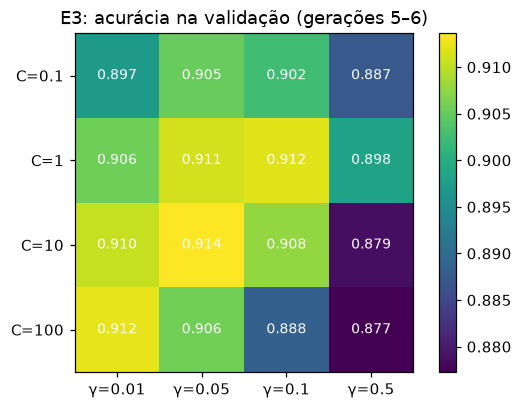

Melhor na validação: C=10, gamma=0.05 → 0.914 (padrão C=1, gamma='scale' → 0.913)


In [8]:
Cs, gammas = [0.1, 1, 10, 100], [0.01, 0.05, 0.1, 0.5]
cols = COLS_BASE + COLS_GOLPES
grade = np.zeros((len(Cs), len(gammas)))
t0 = time.time()
for i, C in enumerate(Cs):
    for j, g in enumerate(gammas):
        _, r = avaliar("", svm(kernel="rbf", C=C, gamma=g), cols, tr=ajuste_tr, te=ajuste_val, guardar=False)
        grade[i, j] = r["acurácia"]
print(f"Grade avaliada em {time.time() - t0:.0f}s")

fig, ax = plt.subplots(figsize=(6, 4))
im = ax.imshow(grade, cmap="viridis")
ax.set_xticks(range(len(gammas)), [f"γ={g}" for g in gammas]); ax.set_yticks(range(len(Cs)), [f"C={c}" for c in Cs])
for i in range(len(Cs)):
    for j in range(len(gammas)):
        ax.text(j, i, f"{grade[i, j]:.3f}", ha="center", va="center", color="white", fontsize=9)
ax.set_title("E3: acurácia na validação (gerações 5–6)"); fig.colorbar(im); plt.show()

i, j = np.unravel_index(grade.argmax(), grade.shape)
melhor_C, melhor_gamma = Cs[i], gammas[j]
_, r_padrao = avaliar("", svm(kernel="rbf"), cols, tr=ajuste_tr, te=ajuste_val, guardar=False)
print(f"Melhor na validação: C={melhor_C}, gamma={melhor_gamma} → {grade[i, j]:.3f} "
      f"(padrão C=1, gamma='scale' → {r_padrao['acurácia']:.3f})")

In [9]:
modelo_final, _ = avaliar("E3: SVM rbf ajustado (base + golpes)", svm(kernel="rbf", C=melhor_C, gamma=melhor_gamma), cols)
tabela(["E2: SVM rbf (base + golpes)", "E3: SVM rbf ajustado (base + golpes)"])

,acurácia,F1,ROC-AUC,tempo (s)
E2: SVM rbf (base + golpes),0.926,0.924,0.976,12.365
E3: SVM rbf ajustado (base + golpes),0.926,0.925,0.977,13.546


**Resultado e interpretação (E3):** o melhor par na validação foi `C = 10`, `gamma = 0,05` (91,4%), praticamente
igual ao padrão (91,3%). No teste, os dois ficaram em **92,6%**. **Hipótese não confirmada:** o ajuste não trouxe ganho
mensurável. Os valores padrão do scikit-learn já estavam perto do ótimo para este problema, e a grade mostra uma região
ampla de bons resultados. Os piores resultados aparecem com gamma alto (0,5), em que a fronteira fica "recortada"
demais (sobreajuste). O modelo ajustado foi mantido como final por ter sido escolhido com um protocolo sem vazamento.

### E4: Quanto o vazamento de dados inflaria o resultado?
- **Hipótese (registrada em 20/10):** dividir as batalhas **aleatoriamente** (sem separar por Pokémon) deixa os mesmos
  Pokémon no treino e no teste, e a acurácia medida fica **maior que a real** (otimista).
- **Alteração:** só a forma de dividir. Mesmo modelo (SVM ajustado), mesmas features, mesmo tamanho de treino e teste.
  - **Com vazamento:** batalhas de treino + teste misturadas e sorteadas (mesmas proporções).
  - **Sem vazamento:** divisão por geração (protocolo oficial).

In [10]:
pool = np.where(treino | teste)[0]
idx_tr, idx_te = train_test_split(pool, test_size=teste.sum(), random_state=SEED, stratify=y[pool])
m_tr = np.zeros(len(y), bool); m_tr[idx_tr] = True
m_te = np.zeros(len(y), bool); m_te[idx_te] = True

vistos = set(bt.a_id[m_tr]) | set(bt.b_id[m_tr])
ambos_vistos = (bt.a_id[m_te].isin(vistos) & bt.b_id[m_te].isin(vistos)).mean()
print(f"Divisão aleatória: {ambos_vistos:.1%} das batalhas de teste têm os DOIS Pokémon presentes no treino")

avaliar("E4: divisão aleatória (com vazamento)", svm(kernel="rbf", C=melhor_C, gamma=melhor_gamma), cols, tr=m_tr, te=m_te)
r = tabela(["E3: SVM rbf ajustado (base + golpes)", "E4: divisão aleatória (com vazamento)"])
r.index = ["Divisão por geração (sem vazamento)", "Divisão aleatória (com vazamento)"]
r

Divisão aleatória: 100.0% das batalhas de teste têm os DOIS Pokémon presentes no treino


,acurácia,F1,ROC-AUC,tempo (s)
Divisão por geração (sem vazamento),0.926,0.925,0.977,13.546
Divisão aleatória (com vazamento),0.925,0.924,0.977,14.268


**Resultado e interpretação (E4), um caso inesperado:** com a divisão aleatória, **100%** das batalhas de teste tinham
os dois Pokémon já vistos no treino, mas a acurácia ficou igual (92,5% × 92,6%). **Hipótese refutada.** Explicação: as
features descrevem a batalha **de forma relativa** (diferenças de atributos, eficácia de tipo, golpes para nocautear) e
**não identificam o Pokémon** (não há nome nem número). Sem identificador, o modelo não tem como "decorar" que um
Pokémon específico vence muito, e por isso ver o mesmo Pokémon no treino não ajuda. Isso é uma boa notícia: indica que
o modelo aprendeu **regras gerais de batalha**, e não os personagens. Mesmo assim, a divisão por geração continua sendo
o protocolo correto, porque é a única que garante que a avaliação corresponde ao uso real (Pokémon novos), como
recomendam Kaufman et al. (2012).

## 5. Análise de erros e casos inesperados (E5)

Modelo analisado: **SVM ajustado com features base + golpes** (E3), no conjunto de teste (gerações 7–9).

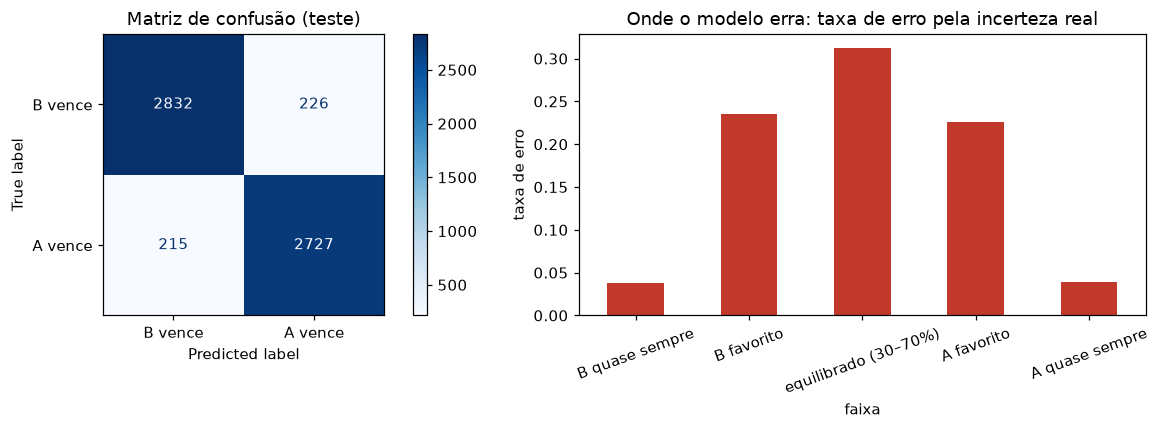

Erros: 441 de 6000 (7.3%)
Erros em confrontos equilibrados: 102 (23.1% de todos os erros)


,mean,size
faixa,,
B quase sempre,0.038,2559
B favorito,0.236,331
equilibrado (30–70%),0.313,326
A favorito,0.226,288
A quase sempre,0.039,2496


In [11]:
d = bt[teste].copy()
Xte = X.loc[teste, cols]
d["score"] = modelo_final.decision_function(Xte)
d["pred"] = modelo_final.predict(Xte)
d["erro"] = d.pred != d.a_vence
nome = pk.set_index("pokeapi_id")["name"]
d["A"], d["B"] = d.a_id.map(nome), d.b_id.map(nome)
d["faixa"] = pd.cut(d.prob_a, [-.01, .1, .3, .7, .9, 1.01],
                    labels=["B quase sempre", "B favorito", "equilibrado (30–70%)", "A favorito", "A quase sempre"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ConfusionMatrixDisplay.from_predictions(d.a_vence, d.pred, display_labels=["B vence", "A vence"], cmap="Blues", ax=axes[0])
axes[0].set_title("Matriz de confusão (teste)")
por_faixa = d.groupby("faixa", observed=True).erro.agg(["mean", "size"])
por_faixa["mean"].plot(kind="bar", ax=axes[1], color="#c0392b")
axes[1].set_ylabel("taxa de erro"); axes[1].set_title("Onde o modelo erra: taxa de erro pela incerteza real")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()
print(f"Erros: {d.erro.sum()} de {len(d)} ({d.erro.mean():.1%})")
print(f"Erros em confrontos equilibrados: {d.loc[d.faixa == 'equilibrado (30–70%)', 'erro'].sum()} "
      f"({d.loc[d.erro, 'faixa'].eq('equilibrado (30–70%)').mean():.1%} de todos os erros)")
por_faixa.round(3)

In [12]:
# Erros mais "confiantes": o modelo tinha certeza e o simulador disse o contrário (confrontos decididos)
confiantes = d[d.erro & ~d.faixa.eq("equilibrado (30–70%)")].assign(conf=lambda t: t.score.abs()).nlargest(8, "conf")
confiantes[["A", "B", "prob_a", "score"]].join(
    Xte[["dif_Speed", "frac_a", "frac_b", "nocaute_a", "nocaute_b", "prioridade_a", "prioridade_b"]]).round(2)

,A,B,prob_a,score,dif_Speed,frac_a,frac_b,nocaute_a,nocaute_b,prioridade_a,prioridade_b
32954,zacian,kleavor,0.24,3.63,53,0.85,0.35,2,3,1,1
31432,marshadow,lokix,0.19,3.47,33,0.76,0.38,2,3,1,1
31889,nickit,calyrex-shadow,0.86,-2.70,-100,0.70,1.07,2,1,1,0
34798,iron-moth,tinkaton,0.00,2.70,16,1.17,0.79,1,2,0,0
34891,gholdengo,dartrix,0.10,2.66,32,0.91,0.31,2,4,0,1
31808,corviknight,cetitan,0.24,2.63,-6,0.66,0.32,2,4,0,1
31582,thwackey,regieleki,0.19,2.47,-120,0.73,0.43,2,3,0,1
33160,ursaluna,silvally,0.29,2.44,-45,0.82,0.42,2,3,1,0


In [13]:
ext = Extrator(pk)

def narrar(a_id, b_id, seed=0):
    la, lb = ext.lutador(a_id), ext.lutador(b_id)
    log = []
    venceu = batalha(la, lb, np.random.default_rng(seed), registro=log)
    print(f"--- {la.nome} (HP {la.hp}, Vel {la.spe}) × {lb.nome} (HP {lb.hp}, Vel {lb.spe})")
    print("    golpes de A:", [g.nome for g in candidatos(la, lb)[:3]], "| golpes de B:", [g.nome for g in candidatos(lb, la)[:3]])
    for linha in log[:8]:
        print("   ", linha)
    print("    vencedor:", la.nome if venceu else lb.nome)

for _, r in confiantes.head(3).iterrows():
    narrar(r.a_id, r.b_id)

--- zacian (HP 167, Vel 158) × kleavor (HP 145, Vel 105)
    golpes de A: ['steel-beam', 'iron-head', 'iron-tail'] | golpes de B: ['stone-edge', 'double-edge', 'rock-blast']
    T1: zacian usa steel-beam → 124 de dano (kleavor: 21/145 HP)
    T1: kleavor usa stone-edge → 66 de dano (zacian: 18/167 HP)
    T2: kleavor usa quick-attack → 22 de dano (zacian: 0/167 HP)
    vencedor: kleavor
--- marshadow (HP 165, Vel 145) × lokix (HP 146, Vel 112)
    golpes de A: ['close-combat', 'superpower', 'stone-edge'] | golpes de B: ['aerial-ace', 'throat-chop', 'lash-out']
    T1: marshadow usa close-combat → 106 de dano (lokix: 40/146 HP)
    T1: lokix usa aerial-ace → 84 de dano (marshadow: 81/165 HP)
    T2: marshadow usa close-combat → 120 de dano (lokix: 0/146 HP)
    vencedor: marshadow
--- nickit (HP 115, Vel 70) × calyrex-shadow (HP 175, Vel 170)
    golpes de A: ['foul-play', 'lash-out', 'sucker-punch'] | golpes de B: ['leaf-storm', 'double-kick', 'double-edge']
    T1: calyrex-shadow usa 

In [14]:
# Casos especiais: quanto o modelo erra em situações que as features não descrevem bem?
idx = pk.set_index("pokeapi_id")
especial = pd.DataFrame({
    "envolve Shedinja (HP = 1)": d.A.eq("shedinja") | d.B.eq("shedinja"),
    "algum lado só tem Struggle (sem golpe útil)": [candidatos(ext.lutador(a), ext.lutador(b))[0].nome == "struggle" or
                                                     candidatos(ext.lutador(b), ext.lutador(a))[0].nome == "struggle"
                                                     for a, b in zip(d.a_id, d.b_id)],
    "o mais lento tem golpe de prioridade": ((Xte.dif_Speed < 0) & (Xte.prioridade_a == 1)) | ((Xte.dif_Speed > 0) & (Xte.prioridade_b == 1)),
    "nocaute em 1 golpe para os dois lados": (Xte.nocaute_a == 1) & (Xte.nocaute_b == 1),
    "velocidade empatada": Xte.dif_Speed == 0,
})
pd.DataFrame({c: {"batalhas": int(m.sum()), "taxa de erro": d.erro[m.values].mean() if m.sum() else np.nan}
              for c, m in especial.items()}).T.assign(**{"taxa de erro geral": d.erro.mean()}).round(3)

,batalhas,taxa de erro,taxa de erro geral
envolve Shedinja (HP = 1),0.0,NaN,0.074
algum lado só tem Struggle (sem golpe útil),101.0,0.020,0.074
o mais lento tem golpe de prioridade,1597.0,0.080,0.074
nocaute em 1 golpe para os dois lados,145.0,0.131,0.074
velocidade empatada,105.0,0.086,0.074


**Interpretação da análise de erros (E5):**
- **Onde o modelo erra:** 7,3% de erro no teste. Nos confrontos em que um lado vence quase sempre, o erro é de só 3,8%.
  Nos **equilibrados** (30–70%), sobe para 31%, e nas faixas intermediárias (70–90%), para cerca de 23%. Ou seja, os erros
  se concentram onde **a sorte decide**. Os equilibrados são só 5,4% do teste, mas respondem por 23% dos erros.
- **Duelo de nocaute em 1 golpe:** quando os dois nocauteiam o outro com um único golpe, o erro quase dobra (13,1% contra
  7,4%), porque o resultado depende só de quem ataca primeiro (velocidade, prioridade, precisão).

**Três erros analisados em detalhe:**
1. **Zacian × Kleavor** (o modelo deu Zacian com confiança alta; o Kleavor vence 76%): o melhor golpe do Zacian é o
   **Steel Beam** (140 de poder), que **custa 50% do HP de quem usa**. As features só medem o dano causado, não esse
   custo. Na batalha narrada, o Zacian quase nocauteia o Kleavor, mas fica com 50% do HP a menos e cai para um Stone
   Edge e um golpe de prioridade (Quick Attack). Revela também uma **limitação do simulador**: a escolha de golpe não
   considera o custo de HP.
2. **Marshadow × Lokix** (modelo: Marshadow; Lokix vence 81%): o Marshadow usa **Close Combat**, que **reduz a própria
   defesa** a cada uso. As features não capturam efeitos colaterais acumulados ao longo dos turnos. Na batalha narrada,
   o Marshadow venceu: um exemplo de que, mesmo em confrontos "decididos", a sorte muda alguns resultados.
3. **Nickit × Calyrex-Shadow** (modelo: Calyrex; o Nickit vence 86%): o caso mais surpreendente. Um Pokémon fraco vence
   um lendário porque tem **golpes Sombrios, 4× efetivos** contra o Calyrex (Psíquico/Fantasma), incluindo **Sucker
   Punch, com prioridade**. Mesmo sendo muito mais lento, ele pode atacar primeiro e nocautear. O modelo sabe que o Nickit
   tem prioridade e golpe forte, mas a diferença enorme de atributos "pesa" mais na fronteira.

**Casos do Checkpoint 1:** com as features de golpes, o modelo **corrigiu** Meowscarada × Skeledirge, mas **continua
errando Pikachu × Gyarados**, outro duelo em que os dois nocauteiam em 1 golpe. Isso reforça que falta ao modelo uma
feature que combine **velocidade e nocaute** ("quem derruba primeiro").

In [15]:
# Casos do Checkpoint 1 (fora do teste, ilustrativos): o modelo sem golpes × o modelo com golpes
from simulador import simular_confronto
id_ = pk.set_index("name")["pokeapi_id"]
for a, b in [("pikachu", "gyarados"), ("slither-wing", "dialga-origin"), ("snorlax", "gengar"), ("meowscarada", "skeledirge")]:
    xa = pd.DataFrame([ext.linha(id_[a], id_[b])])
    s1 = modelos_e1["rbf"].decision_function(xa[COLS_BASE])[0]
    s2 = modelo_final.decision_function(xa[cols])[0]
    real = simular_confronto(ext.lutador(id_[a]), ext.lutador(id_[b]), np.random.default_rng(SEED), 201) / 201
    fav = lambda s: a if s > 0 else b
    print(f"{a:>13} × {b:<14} | simulador: {a} vence {real:4.0%} | sem golpes: {fav(s1):<13} | com golpes: {fav(s2)}")

      pikachu × gyarados       | simulador: pikachu vence 100% | sem golpes: gyarados      | com golpes: gyarados
 slither-wing × dialga-origin  | simulador: slither-wing vence  24% | sem golpes: dialga-origin | com golpes: dialga-origin
      snorlax × gengar         | simulador: snorlax vence  95% | sem golpes: snorlax       | com golpes: snorlax
  meowscarada × skeledirge     | simulador: meowscarada vence  17% | sem golpes: meowscarada   | com golpes: skeledirge


## 6. Resumo dos resultados

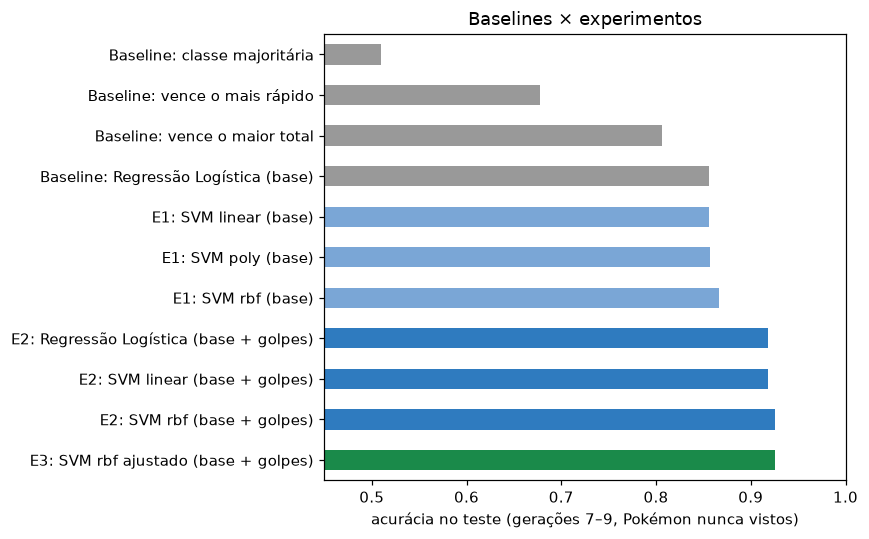

,acurácia,F1,ROC-AUC,tempo (s)
Baseline: classe majoritária,0.510,0.000,0.500,0.046
Baseline: vence o mais rápido,0.678,0.675,0.713,0.018
Baseline: vence o maior total,0.806,0.802,0.898,0.000
Baseline: Regressão Logística (base),0.856,0.853,0.936,0.035
E1: SVM linear (base),0.856,0.853,0.936,12.006
E1: SVM poly (base),0.857,0.854,0.926,12.216
E1: SVM rbf (base),0.866,0.863,0.935,16.083
E2: Regressão Logística (base + golpes),0.918,0.916,0.976,0.050
E2: SVM linear (base + golpes),0.918,0.916,0.975,10.034
E2: SVM rbf (base + golpes),0.926,0.924,0.976,12.365


In [16]:
ordem = ["Baseline: classe majoritária", "Baseline: vence o mais rápido", "Baseline: vence o maior total",
         "Baseline: Regressão Logística (base)", "E1: SVM linear (base)", "E1: SVM poly (base)", "E1: SVM rbf (base)",
         "E2: Regressão Logística (base + golpes)", "E2: SVM linear (base + golpes)", "E2: SVM rbf (base + golpes)",
         "E3: SVM rbf ajustado (base + golpes)"]
final = tabela(ordem)
fig, ax = plt.subplots(figsize=(8, 5))
final["acurácia"].plot(kind="barh", ax=ax, color=["#999"] * 4 + ["#7aa6d6"] * 3 + ["#2f7bbf"] * 3 + ["#1a8a4a"])
ax.set_xlim(.45, 1); ax.set_xlabel("acurácia no teste (gerações 7–9, Pokémon nunca vistos)")
ax.set_title("Baselines × experimentos"); ax.invert_yaxis(); plt.tight_layout(); plt.show()
final

In [17]:
import joblib, json
joblib.dump(modelo_final, "../modelos/svm_duelo_v2.joblib")
json.dump({"features": cols, "C": melhor_C, "gamma": melhor_gamma}, open("../modelos/svm_duelo_v2.json", "w"))
print("Modelo salvo em modelos/svm_duelo_v2.joblib (usado pela demo batalhar.py)")

Modelo salvo em modelos/svm_duelo_v2.joblib (usado pela demo batalhar.py)


## 7. Conclusões provisórias e limitações

**Conclusões provisórias**
1. O SVM final (RBF, `C = 10`, `gamma = 0,05`, 15 features) acerta o favorito em **92,6%** das batalhas entre Pokémon
   **nunca vistos no treino** (gerações 7–9), contra 67,8% de "vence o mais rápido" e 80,6% de "vence o maior total".
2. **O que mais importou foram as features, não o algoritmo:** incluir informação sobre os golpes rendeu +6 pontos; trocar o
   kernel ou ajustar C e gamma rendeu no máximo 1 ponto.
3. O SVM RBF supera os modelos lineares de forma **consistente, mas pequena** (cerca de 1 ponto), indicando um problema
   majoritariamente linear com algumas interações.
4. O modelo aprendeu **regras gerais de batalha**, e não identidades de Pokémon (E4).
5. Os erros restantes se concentram em confrontos **decididos pela sorte** e em **duelos de nocaute em 1 golpe**, em que a
   ordem de ataque decide tudo.

**Limitações**
- **Simulador simplificado:** sem habilidades, itens, golpes de status, trocas ou estratégia. O modelo aprende as regras
  **do nosso simulador**, não o jogo competitivo real.
- **A escolha de golpe do simulador é gulosa** e ignora custos (Steel Beam) e efeitos colaterais (Close Combat), o que
  gera alguns resultados pouco realistas (E5, casos 1 e 2).
- **Features de golpes calculadas com a mesma fórmula do simulador:** o ganho do E2 mostra que o modelo se beneficia de
  conhecer a mecânica. Em outro simulador (ou no jogo real), essas features teriam de ser recalculadas.
- **Rótulo por maioria em 21 simulações:** nos confrontos equilibrados, o rótulo é quase aleatório, o que limita o acerto
  máximo possível.
- **Uma única divisão de teste** (gerações 7–9). Repetir com outras divisões (por exemplo, testar nas gerações 1–3) daria
  uma estimativa mais robusta da variação.

**Próximos passos**
- Criar uma feature que combine velocidade, prioridade e nocaute ("quem derruba primeiro") e testar se resolve os duelos
  de 1 golpe.
- Exibir a probabilidade de vitória na arena (calibração do score, Platt, 1999).
- Integrar o modelo v2 à aplicação web para dois jogadores.